# Fish B: EODs with the highest, typical and lowest recorded / predicted ratio (4-fish, Kaden masks)

**EODs.** Fish B's EODs in the 1365-EOD clean emitter set (`EOD_clean_emitter_set_4fish_kaden.ipynb`).

**Ratio.** As in `EOD_gain_ratios_top2_fish_pair_ls_4fish_kaden.ipynb`, my model: on the 2 pairs with the largest recorded
|V| (main phase), $g = |V_\text{rec}| / |V_\text{pred}|$ with my unit-current prediction for fish B. The **EOD ratio** is the
mean of its 2 ratios. EODs are ranked by it; the pair-corrected value $g / b_p$ (pair factors of the all-video least-squares
fit) is shown too, since the pairs differ.

**Picks.** The 10 highest, the 10 closest to the median and the 10 lowest EOD ratios, keeping EODs at least 100 frames apart
within a video so that one burst does not fill a group.

**Each figure.** Top and middle rows as in the clean emitter set figures (tank with fish B's 2 nearest pairs joined, zooms,
main-phase shape, unit-current |v| of every fish on the 2 nearest pairs, recorded traces). Bottom row, new:
- left: fish B's EOD ratios (all EODs): histogram, median (black), 10–90% (grey band); this EOD in red;
- middle and right: fish B's ratios on each of this EOD's 2 loudest pairs alone (only EODs that have that pair among their 2
  loudest), same marks.

**Denis' model, for comparison** (EODs still picked by my ratio): his analytic prediction for fish B (`predicted_ptp`, his
units, my mask midline) against his recorded peak-to-peak (`recorded_ptp`), from `denis_predicted_voltages.npz`. His ratio uses
the 2 pairs with the largest recorded |peak-to-peak| (usually the same 2 pairs). Extra rows:
- Denis, volts: recorded peak-to-peak (black) and his fish B prediction × his fish B and pair factors $a_B b_p$ (least squares on
  the 1365 set, `EOD_gain_ratios_top2_fish_pair_ls_4fish_kaden.ipynb`); and the shape of both (each scaled to max |v| = 1, L2);
- Denis' ratio distributions, as for mine.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Rectangle
from matplotlib.backends.backend_pdf import PdfPages
from model_voltages_4fish import Masks                                # imports mask_metrics, which sets the Agg backend
from eod_assign import load_electrode_pairs, recorded_pair_traces_all
%matplotlib inline

BASE, LET, P = 'results/eod_assign_4fish_kaden', 'ABCD', 912
SRC = f'{BASE}/clean_emitter_set'
OUT = f'{SRC}/fish_B_ratio_examples'; os.makedirs(f'{OUT}/per_frame', exist_ok=True)
KADEN = 'data/track_Kaden/results_{t}_full/video2024-02-20T{t}/outputs/video2024-02-20T{t}.pkl'
ELECTRODES = 'data/electrodes/electrodes_signed_px_coord_4-fish.csv'
EL = pd.read_csv(ELECTRODES).sort_values('pair').reset_index(drop=True)
PIDS = [p for p, _, _ in load_electrode_pairs(ELECTRODES, P)]
PX_CM = P / 60
FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E'}
L_CM = {'A': 15.65, 'B': 13.10, 'C': 9.82, 'D': 8.51}
N_PER, MIN_DF, HL = 10, 100, '#C8361E'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})

PASS = pd.read_csv(f'{SRC}/clean_emitter_all_passing.csv')
RT = pd.read_csv(f'{SRC}/gain_ratios_top2/ratios_mine_1365.csv'); RT = RT[RT.kept & (RT.fish == 'B')]
F = pd.read_csv(f'{SRC}/gain_ratios_top2/fish_and_pair_factors.csv')
F = F[(F.set == '1365 passing') & (F.model == 'mine')].set_index('factor').LS
B_PAIR = np.array([F[f'pair {p}'] for p in range(1, 11)]); A_B = F['fish B']
RT['gain_corr'] = RT.gain / B_PAIR[RT.pair - 1]
RD = pd.read_csv(f'{SRC}/gain_ratios_top2/ratios_Denis_1365.csv'); RD = RD[RD.kept & (RD.fish == 'B')]
FD = pd.read_csv(f'{SRC}/gain_ratios_top2/fish_and_pair_factors.csv')
FD = FD[(FD.set == '1365 passing') & (FD.model == 'Denis')].set_index('factor').LS
D_PAIR = np.array([FD[f'pair {p}'] for p in range(1, 11)]); D_A_B = FD['fish B']
ED = RD.groupby(['video', 'row']).agg(d_ratio=('gain', 'mean'), d_pairs=('pair', lambda s: ','.join(map(str, s))),
                                      d_ratios=('gain', lambda s: ','.join(f'{v:.5f}' for v in s))).reset_index()
E = RT.groupby(['video', 'row']).agg(ratio=('gain', 'mean'), ratio_corr=('gain_corr', 'mean'), n=('gain', 'size'),
                                     pairs=('pair', lambda s: ','.join(map(str, s))), ratios=('gain', lambda s: ','.join(f'{v:.3f}' for v in s))).reset_index()
E = E.merge(PASS[PASS.fish == 'B'], on=['video', 'row'], how='left').merge(ED, on=['video', 'row'], how='left')
MED, D_MED = E.ratio.median(), E.d_ratio.median()
E['d_percentile'] = [(E.d_ratio < v).mean() * 100 if np.isfinite(v) else np.nan for v in E.d_ratio]
from scipy.stats import spearmanr
ok = E.d_ratio.notna()
print(f'Denis: fish B EOD ratio median {D_MED:.5f}, 10–90% {E.d_ratio.quantile(0.1):.5f}–{E.d_ratio.quantile(0.9):.5f}; '
      f'Spearman correlation of the EOD ratios mine vs Denis over {ok.sum()} EODs: {spearmanr(E.ratio[ok], E.d_ratio[ok])[0]:.2f}; '
      f'same 2 loudest pairs (as a set) in {np.mean([set(a.split(",")) == set(b.split(",")) for a, b in zip(E.pairs[ok], E.d_pairs[ok])]) * 100:.0f}% of EODs')
print(f'fish B: {len(E)} EODs; EOD ratio median {MED:.3f}, 10–90% {E.ratio.quantile(0.1):.3f}–{E.ratio.quantile(0.9):.3f}, '
      f'min {E.ratio.min():.3f}, max {E.ratio.max():.3f}; all-video fish B factor a_B = {A_B:.3f}')

def pick(order):
    chosen = []
    for _, r in E.loc[order].iterrows():
        if len(chosen) == N_PER: break
        if any(r.video == q.video and abs(r.Frame - q.Frame) < MIN_DF for q in chosen): continue
        chosen.append(r)
    return pd.DataFrame(chosen)
G = {'highest': pick(E.ratio.sort_values(ascending=False).index),
     'median': pick((E.ratio - MED).abs().sort_values().index),
     'lowest': pick(E.ratio.sort_values().index)}
PK = pd.concat([g.assign(group=k, rank_in_group=np.arange(1, len(g) + 1)) for k, g in G.items()], ignore_index=True)
PK['percentile'] = [(E.ratio < v).mean() * 100 for v in PK.ratio]
PK.to_csv(f'{OUT}/fish_B_ratio_examples.csv', index=False)
display(PK[['group', 'rank_in_group', 'video', 'Frame', 'row', 'ratio', 'percentile', 'ratio_corr', 'pairs', 'ratios',
            'd_ratio', 'd_percentile', 'd_pairs', 'nearest_pair', 'second_pair', 'dist_nearest_cm', 'gap_cm', 'L2_fish', 'L2_next_best', 'rec_max_V']].round(3))
print('per group: videos', {k: g.video.value_counts().to_dict() for k, g in G.items()})
print('per group: loudest pairs', {k: g.pairs.value_counts().to_dict() for k, g in G.items()})
print('per group: median percentile of the EOD in Denis\' ratios', PK.groupby('group', sort=False).d_percentile.median().round(0).to_dict())

Denis: fish B EOD ratio median 0.00318, 10–90% 0.00260–0.00516; Spearman correlation of the EOD ratios mine vs Denis over 725 EODs: 0.83; same 2 loudest pairs (as a set) in 99% of EODs
fish B: 725 EODs; EOD ratio median 0.290, 10–90% 0.209–0.370, min 0.164, max 1.247; all-video fish B factor a_B = 0.358


,group,rank_in_group,video,Frame,row,ratio,percentile,ratio_corr,pairs,ratios,d_ratio,d_percentile,d_pairs,nearest_pair,second_pair,dist_nearest_cm,gap_cm,L2_fish,L2_next_best,rec_max_V
0,highest,1,15_16_23,46824,47354,1.247,99.862,1.178,"8,1","0.736,1.758",0.008,99.310,"8,1",8,1,2.143,44.631,0.451,1.597,0.132
1,highest,2,15_16_23,58900,58595,0.816,99.448,0.764,"8,1","0.586,1.046",0.006,97.517,"8,1",8,1,2.143,45.752,0.524,1.709,0.088
2,highest,3,05_52_55,45011,38148,0.687,99.034,0.644,"8,1","0.482,0.893",0.005,90.207,"8,1",8,1,1.895,40.450,0.658,1.839,0.077
3,highest,4,15_16_23,23537,24822,0.678,98.897,0.916,"2,3","0.520,0.835",0.009,99.862,"2,3",3,2,2.594,36.369,0.437,1.825,0.067
4,highest,5,19_16_25,51787,51121,0.646,98.483,0.688,"3,4","0.349,0.943",0.006,97.655,"3,4",3,4,4.168,18.658,0.650,2.034,0.077
5,highest,6,19_16_25,43938,43380,0.645,98.345,0.669,"10,7","0.755,0.535",0.007,99.034,"10,7",10,7,3.048,10.080,0.521,1.278,0.216
6,highest,7,19_16_25,45889,45656,0.622,98.069,0.614,"7,10","0.654,0.589",0.007,99.172,"7,10",7,10,2.921,21.231,0.391,1.679,0.174
7,highest,8,19_16_25,51194,50353,0.616,97.931,0.596,"6,10","0.708,0.525",0.009,99.724,"6,10",6,10,3.186,13.545,0.351,1.755,0.156
8,highest,9,19_16_25,45225,44759,0.595,97.517,0.629,"10,7","0.750,0.440",0.007,98.621,"10,7",7,10,2.250,11.025,0.422,1.509,0.222
9,highest,10,19_16_25,44244,43667,0.573,97.241,0.601,"10,7","0.701,0.445",0.006,97.931,"10,7",7,10,2.178,13.694,0.413,1.337,0.183


per group: videos {'highest': {'19_16_25': 6, '15_16_23': 3, '05_52_55': 1}, 'median': {'15_16_23': 9, '06_52_55': 1}, 'lowest': {'06_52_55': 6, '05_52_55': 2, '15_16_23': 2}}
per group: loudest pairs {'highest': {'8,1': 3, '10,7': 3, '2,3': 1, '3,4': 1, '7,10': 1, '6,10': 1}, 'median': {'10,2': 6, '2,10': 2, '9,1': 1, '8,9': 1}, 'lowest': {'3,10': 5, '2,10': 5}}
per group: median percentile of the EOD in Denis' ratios {'highest': 99.0, 'median': 57.0, 'lowest': 19.0}


## Figures

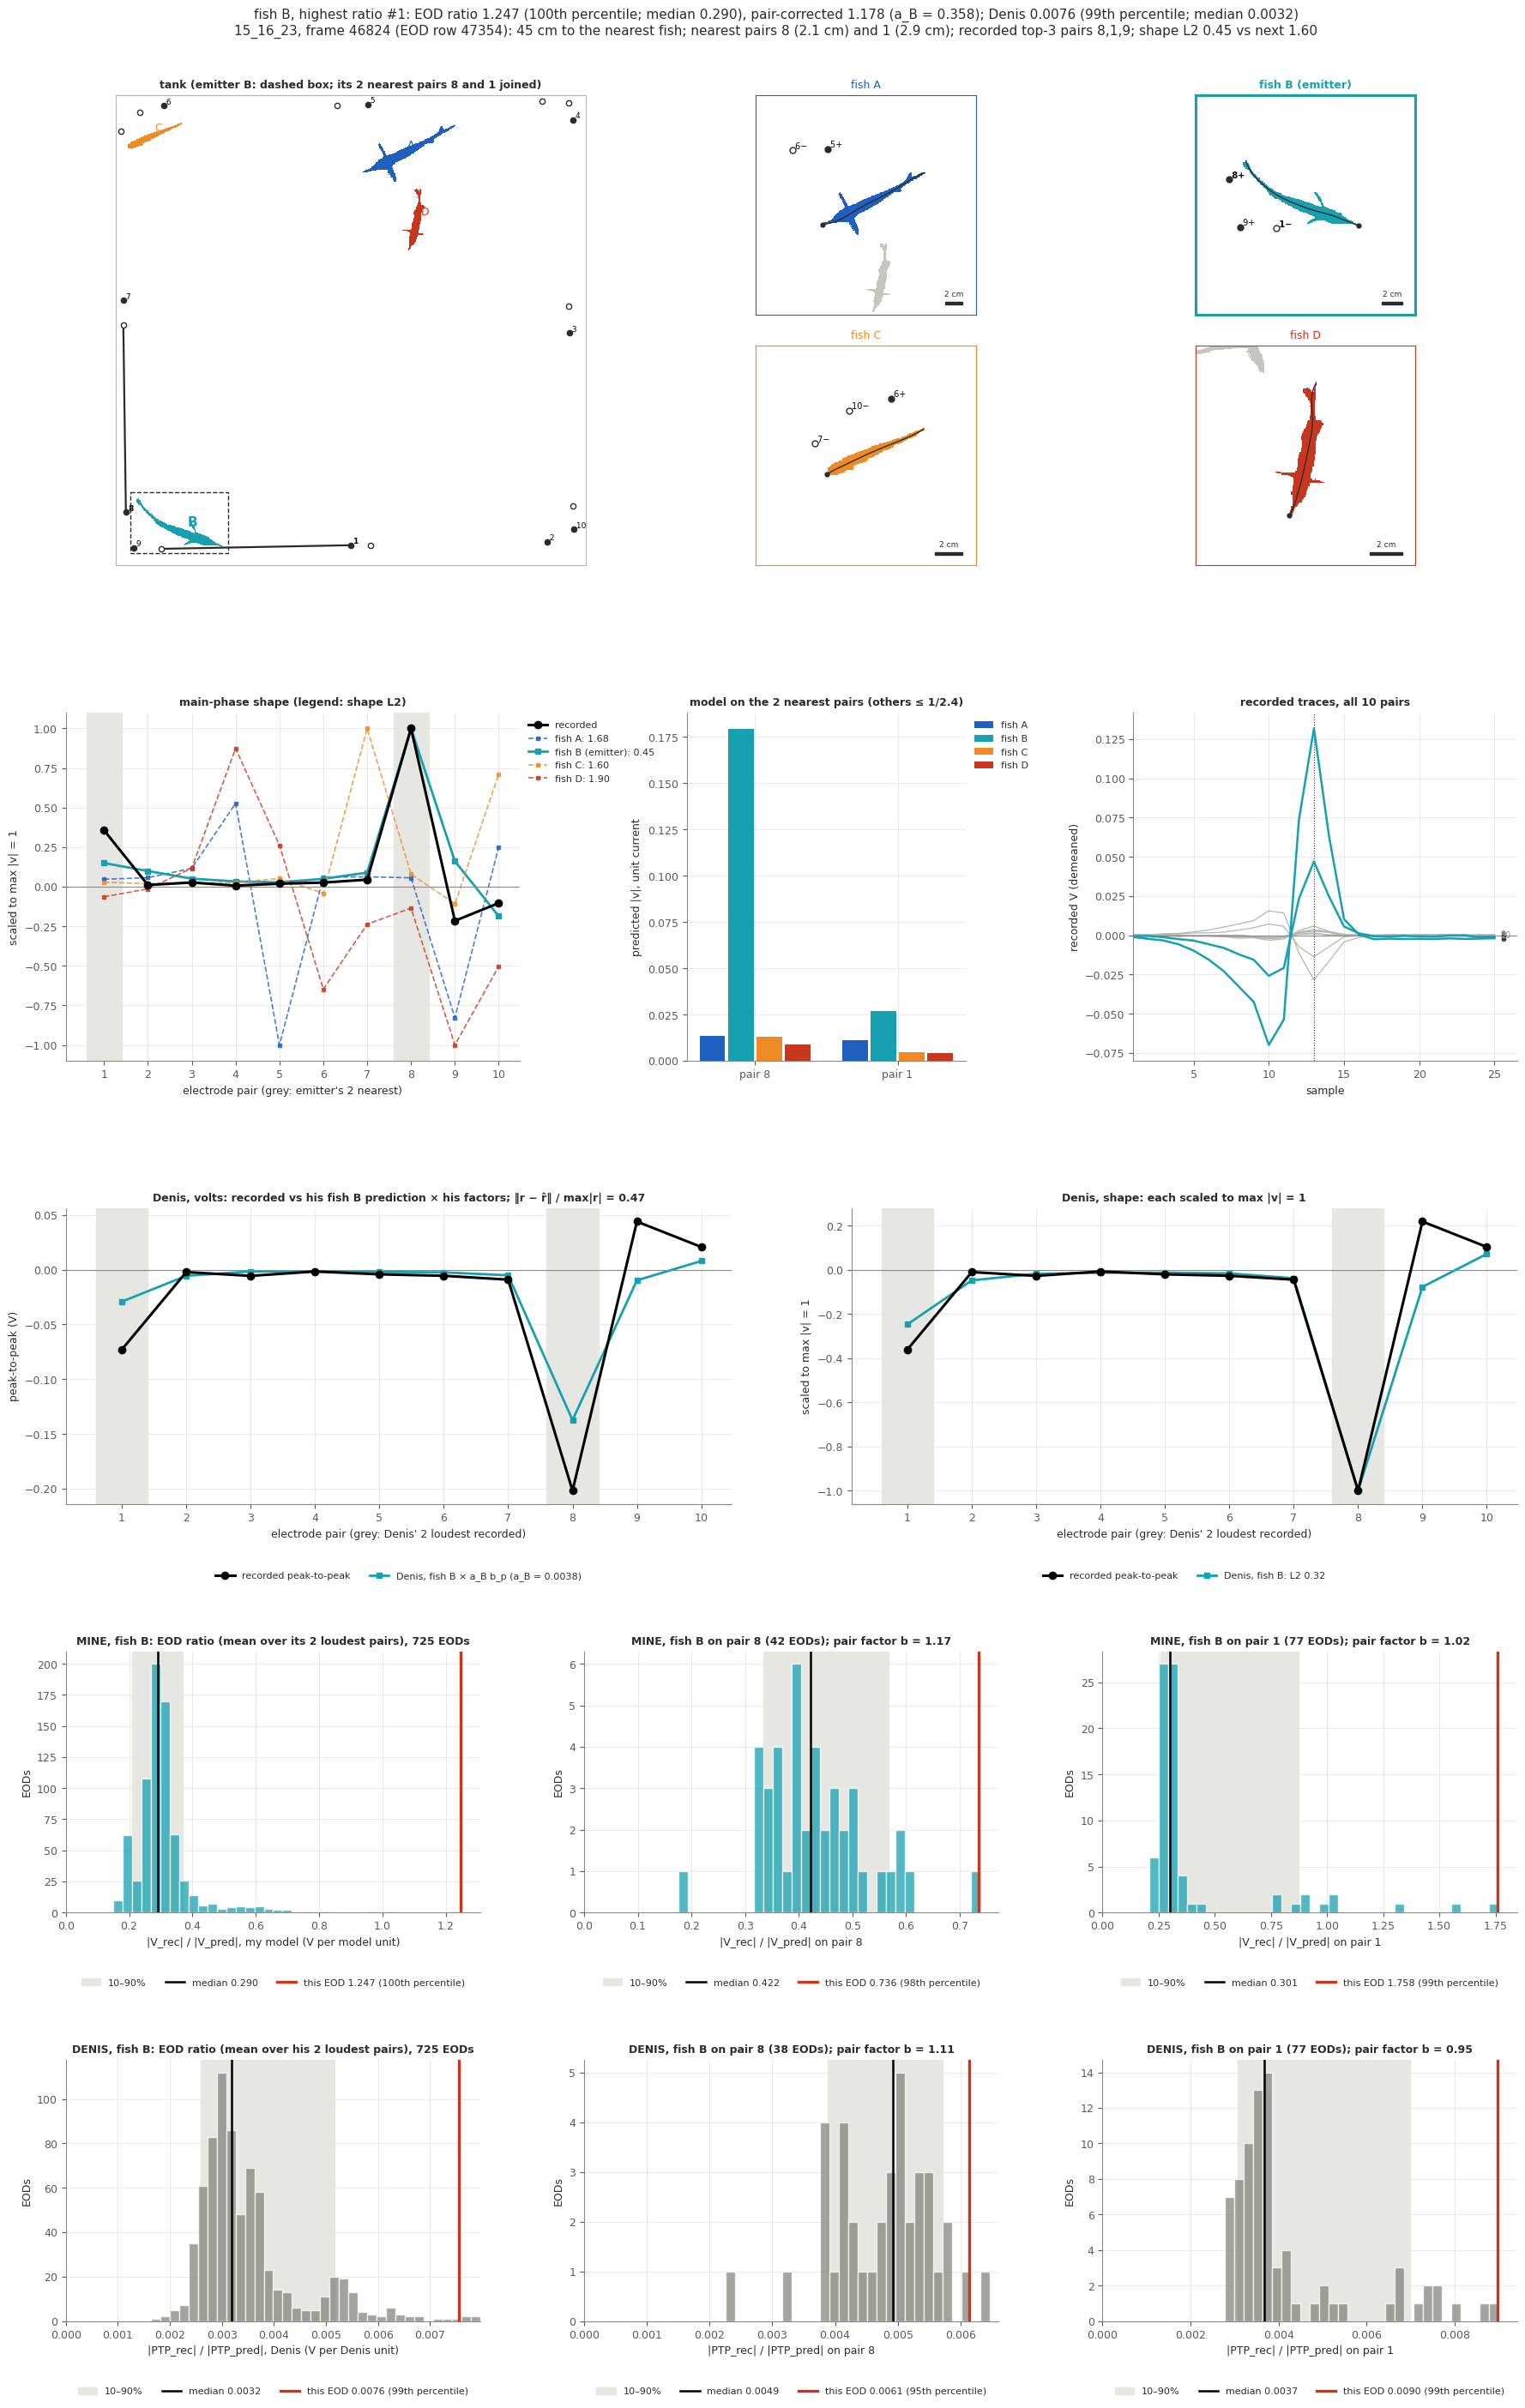

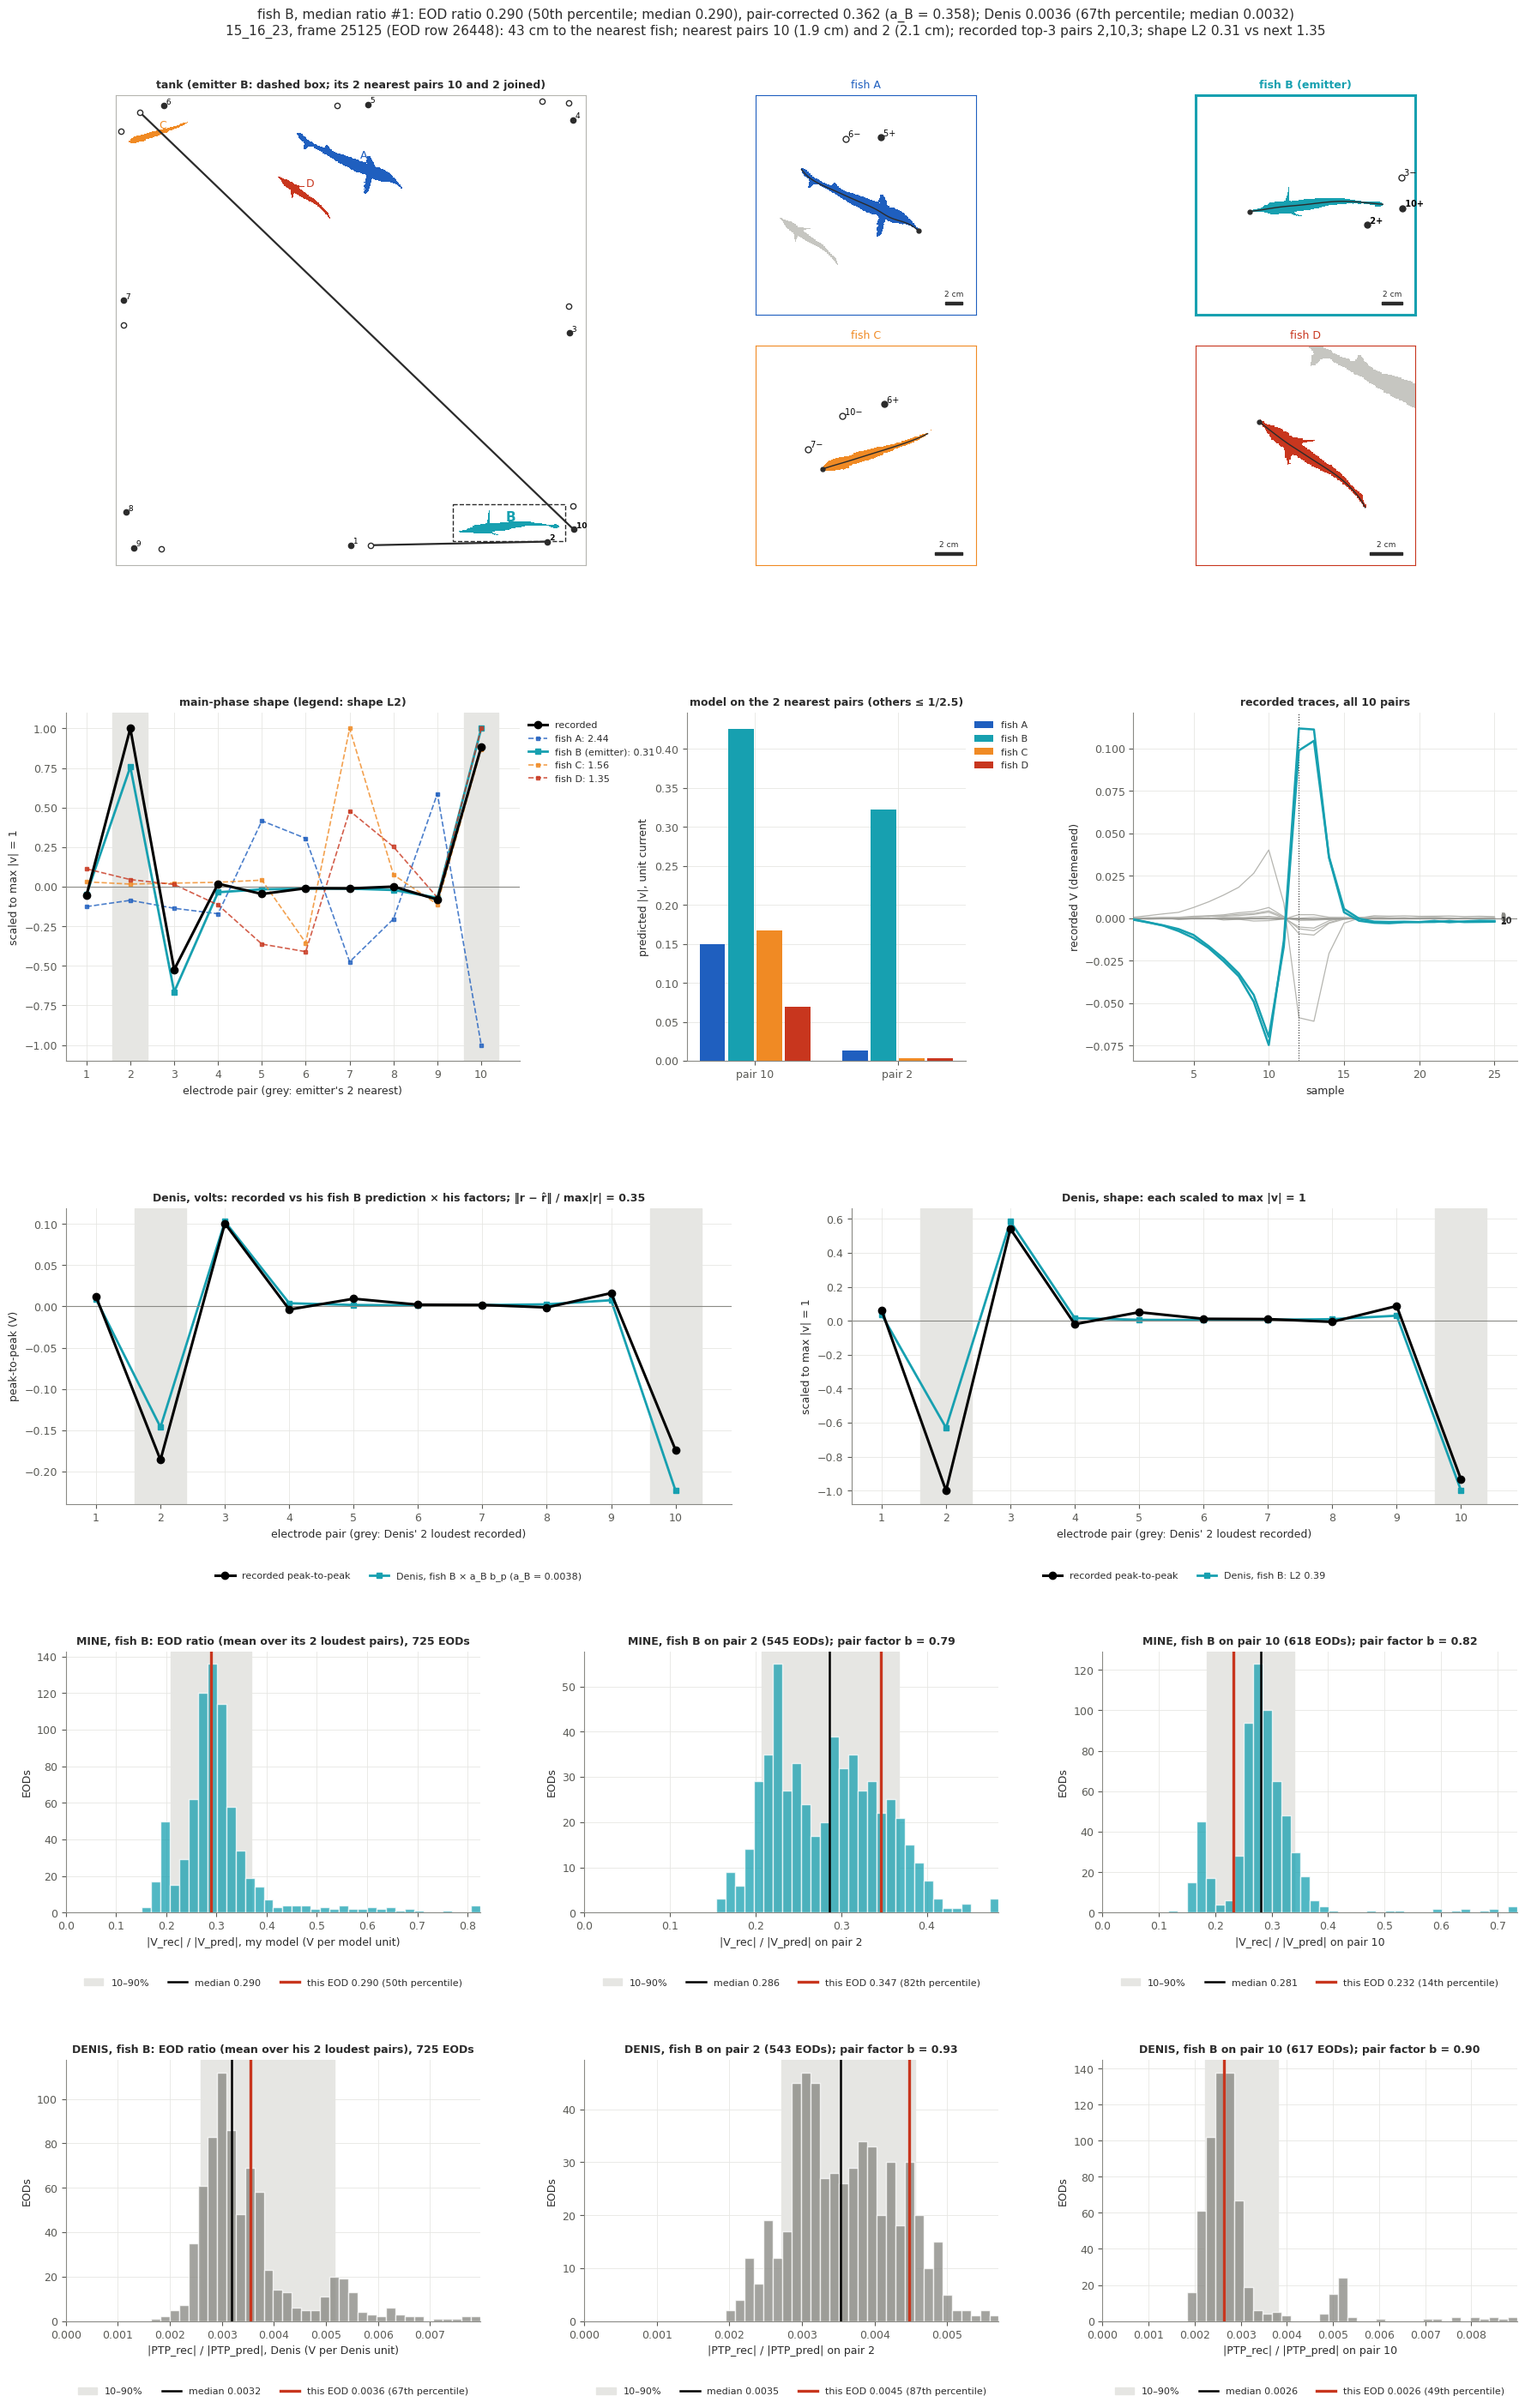

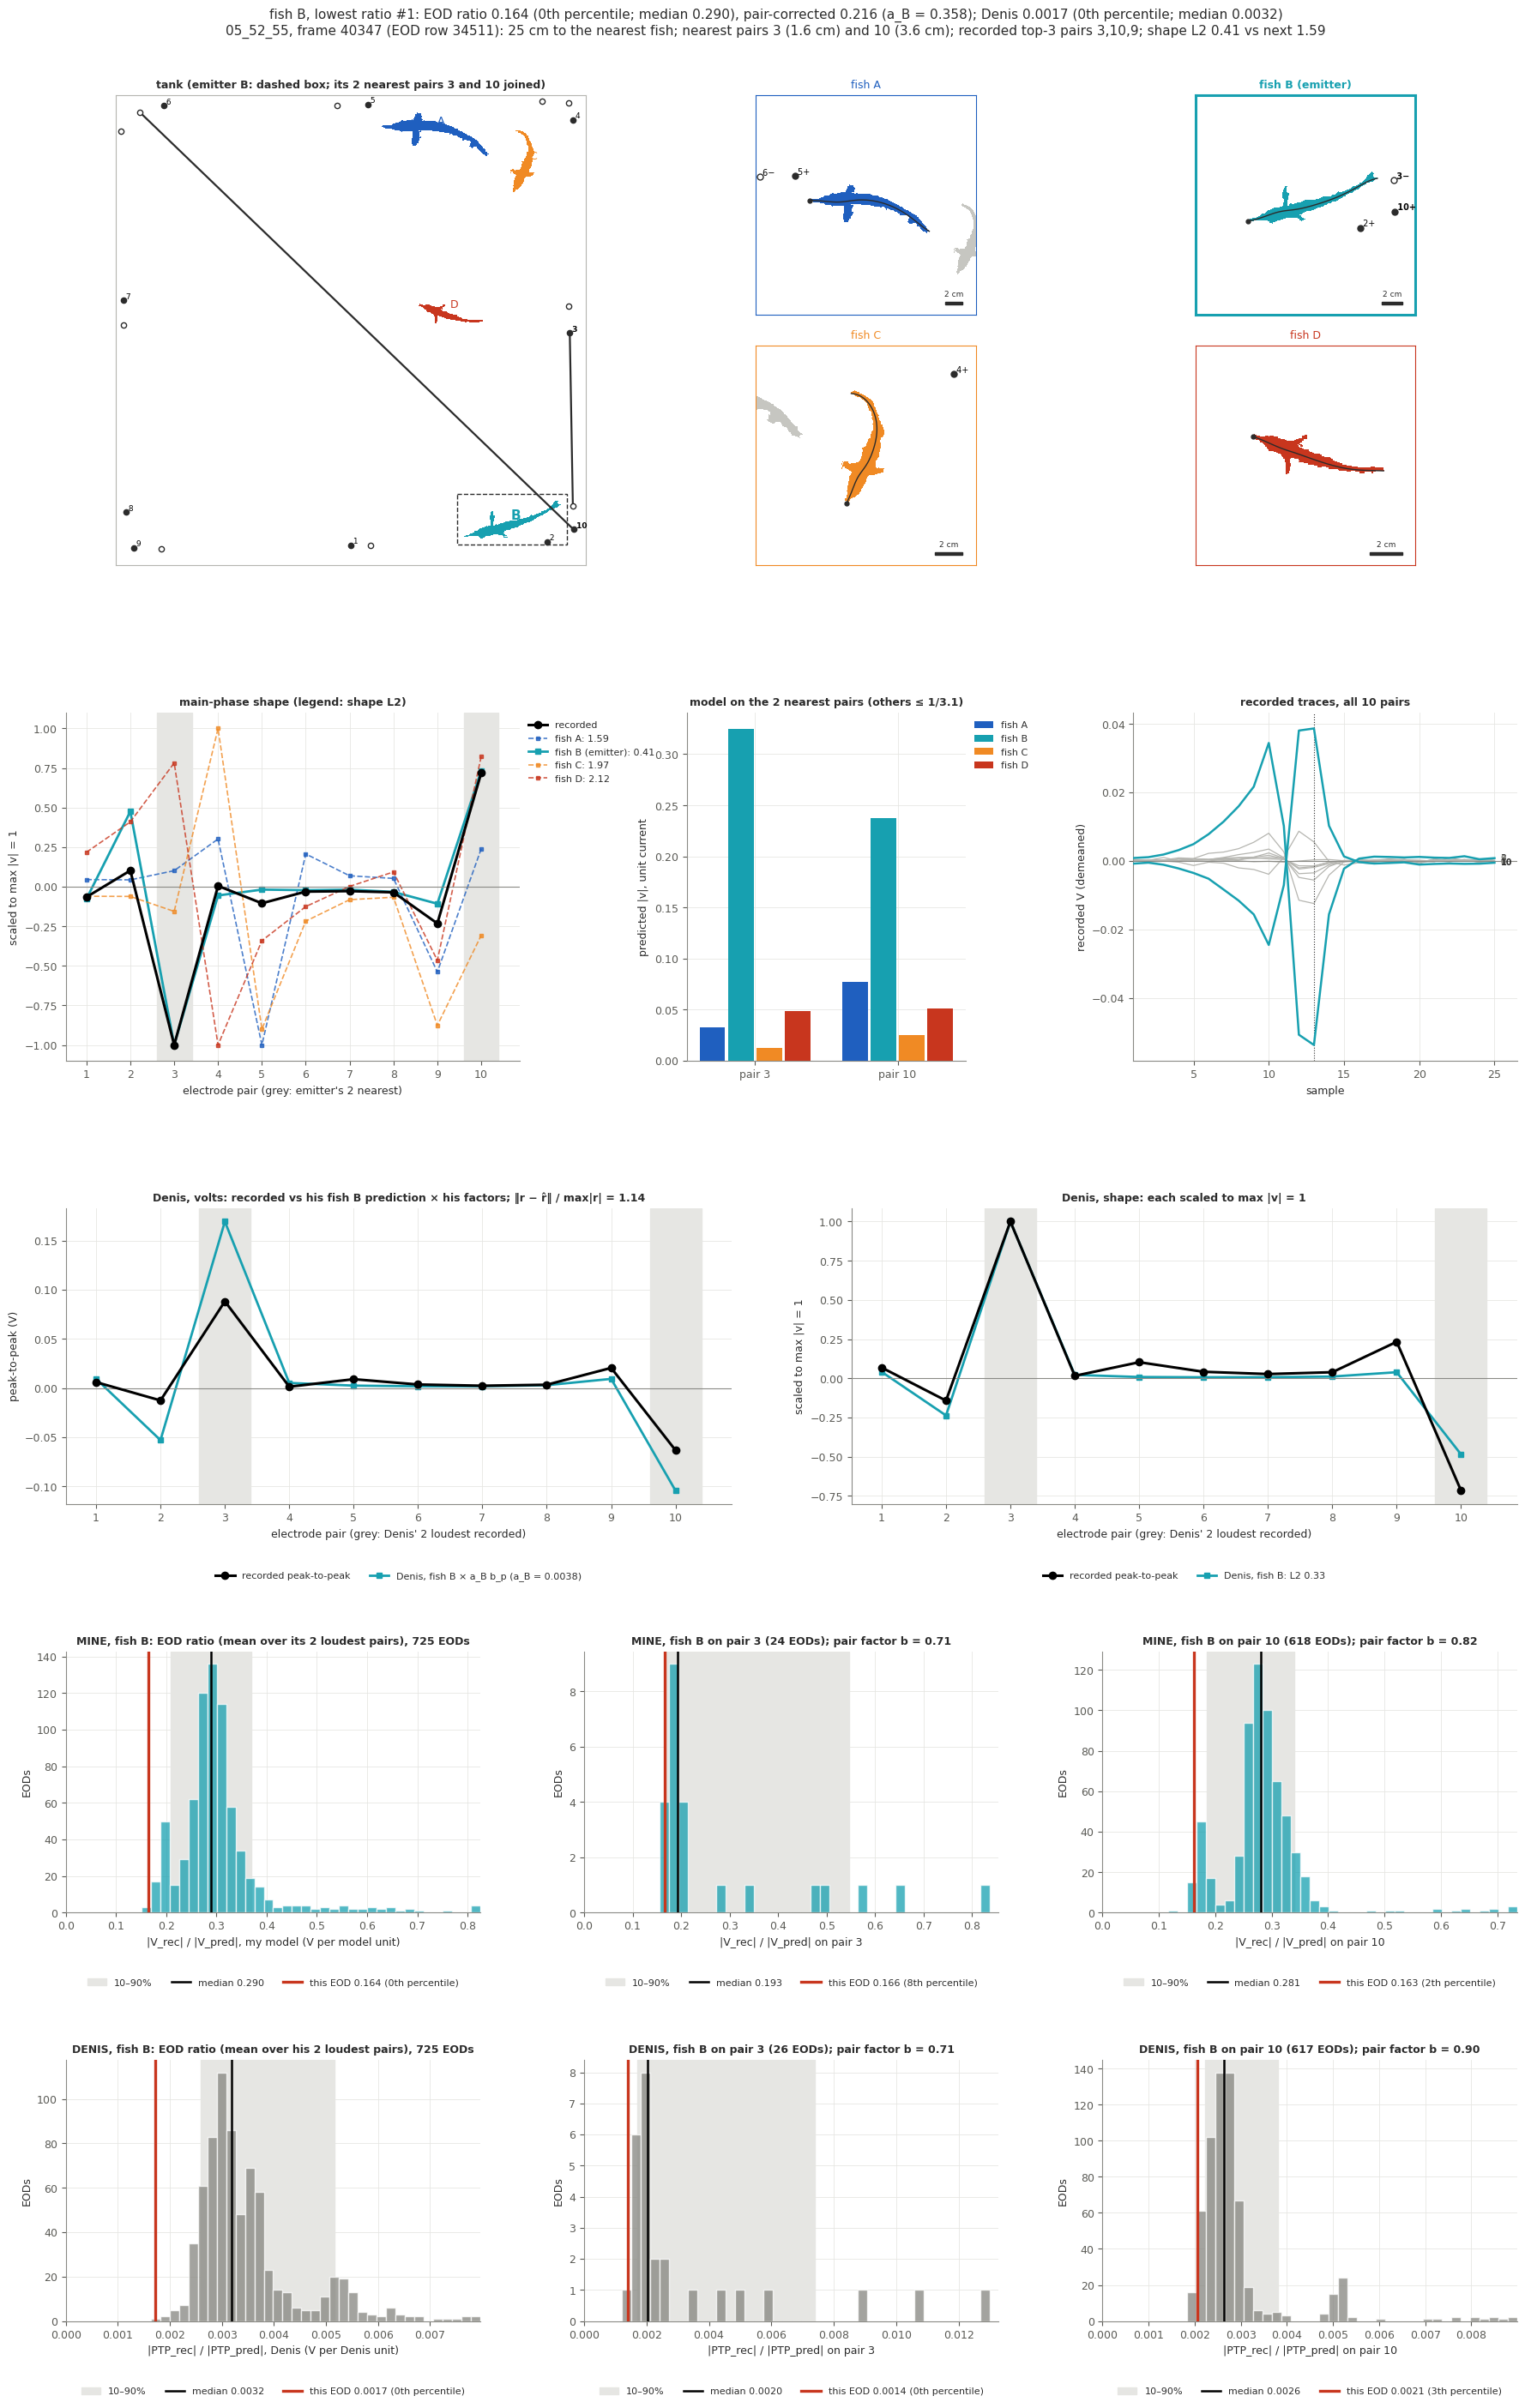

30 figures -> results/eod_assign_4fish_kaden/clean_emitter_set/fish_B_ratio_examples/fish_B_ratio_examples.pdf and results/eod_assign_4fish_kaden/clean_emitter_set/fish_B_ratio_examples/per_frame/


In [2]:
masks, mids, TR, MM, DREC, DPRED = {}, {}, {}, {}, {}, {}
for t in PK.video.unique():
    g = PK[PK.video == t]
    mk = Masks(dict(identity='kaden', masks=KADEN.format(t=t)))
    for k in g.Frame.unique(): masks[(t, int(k))] = mk(int(k))
    del mk
    z = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); idx = {int(k): i for i, k in enumerate(z['frames'])}
    for k in g.Frame.unique(): mids[(t, int(k))] = z['mids'][idx[int(k)]] * (P - 1)
    rows = g.row.to_numpy()
    df = pd.read_csv(f'data/4 fish/Data_4fish_2024-02-20T{t}.csv', usecols=[f'electrode_{p}_time_{i}' for p in PIDS for i in range(1, 26)])
    Vt = recorded_pair_traces_all(df.iloc[rows], PIDS, 25); del df
    pv = np.load(f'{BASE}/{t}/predicted_voltages.npz')
    dv = np.load(f'{BASE}/{t}/denis_predicted_voltages.npz', allow_pickle=True)
    for k, rw in enumerate(rows):
        TR[(t, int(rw))] = Vt[k]; MM[(t, int(rw))] = pv['mine_unit_current'][rw]
        DREC[(t, int(rw))] = dv['recorded_ptp'][rw]; DPRED[(t, int(rw))] = dv['predicted_ptp'][rw, LET.index('B')]

def draw_electrodes(ax, hit_pairs, lim=None, fs=6.5, ms=4.5):
    for _, e in EL.iterrows():
        pp = (e.x1, e.y1) if str(e.pol1).strip() == '+' else (e.x2, e.y2)
        mm_ = (e.x2, e.y2) if str(e.pol1).strip() == '+' else (e.x1, e.y1)
        hit = int(e.pair) in hit_pairs
        if lim is None and hit: ax.plot([pp[0], mm_[0]], [pp[1], mm_[1]], color='#2b2b2b', lw=1.6, zorder=2)
        for pt, filled in ((pp, True), (mm_, False)):
            if lim is not None and not (lim[0] <= pt[0] <= lim[1] and lim[2] <= pt[1] <= lim[3]): continue
            ax.plot(*pt, 'o', ms=ms, mfc='#2b2b2b' if filled else 'white', mec='#2b2b2b', mew=1, zorder=3)
            if filled or lim is not None:
                ax.text(pt[0], pt[1], f' {int(e.pair)}' + ('' if lim is None else ('+' if filled else '−')), fontsize=fs,
                        color='#000000', fontweight='bold' if hit else 'normal', va='bottom', zorder=3)

def tank(ax, r, m, near):
    img = np.ones((P, P, 3))
    for j, f in enumerate(LET): img[m[j]] = to_rgb(FISH_COL[f])
    ax.imshow(img, origin='upper', extent=(-0.5, P - 0.5, P - 0.5, -0.5), interpolation='nearest')
    for j, f in enumerate(LET):
        if m[j].any():
            yy, xx = np.nonzero(m[j])
            ax.text(xx.mean() + 18, yy.mean() - 18, f, fontsize=11 if f == r.fish else 9, color=FISH_COL[f],
                    fontweight='bold' if f == r.fish else 'normal', ha='center', va='center')
    j = LET.index(r.fish)
    if m[j].any():
        yy, xx = np.nonzero(m[j])
        ax.add_patch(Rectangle((xx.min() - 12, yy.min() - 12), xx.max() - xx.min() + 24, yy.max() - yy.min() + 24, fill=False, ec='#2b2b2b', lw=1, ls='--'))
    draw_electrodes(ax, near)
    ax.set(xlim=(0, P), ylim=(P, 0), xticks=[], yticks=[], aspect='equal'); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color('#b5b5b0')
    ax.set_title(f'tank (emitter {r.fish}: dashed box; its 2 nearest pairs {near[0]} and {near[1]} joined)', fontsize=9)

def zoom(ax, r, m, f, ml, near):
    j = LET.index(f)
    if not m[j].any():
        ax.axis('off'); ax.text(0.5, 0.5, f'fish {f}: no mask', ha='center', transform=ax.transAxes); return
    yy, xx = np.nonzero(m[j]); cy, cx = yy.mean(), xx.mean(); h = 0.8 * L_CM[f] * PX_CM
    x0, x1, y0, y1 = cx - h, cx + h, cy - h, cy + h
    img = np.ones((P, P, 3))
    for jj, g in enumerate(LET): img[m[jj]] = to_rgb(FISH_COL[g]) if g == f else (0.78, 0.78, 0.76)
    ax.imshow(img, origin='upper', extent=(-0.5, P - 0.5, P - 0.5, -0.5), interpolation='nearest')
    if np.isfinite(ml[j]).all():
        ax.plot(ml[j][:, 1], ml[j][:, 0], color='#2b2b2b', lw=1); ax.plot(ml[j][-1, 1], ml[j][-1, 0], 'o', ms=3.5, color='#2b2b2b')
    draw_electrodes(ax, near if f == r.fish else [], lim=(x0, x1, y0, y1), fs=7, ms=5)
    sb = 2 * PX_CM
    ax.add_patch(Rectangle((x1 - 0.06 * 2 * h - sb, y1 - 0.06 * 2 * h), sb, 0.012 * 2 * h, color='#2b2b2b'))
    ax.text(x1 - 0.06 * 2 * h - sb / 2, y1 - 0.075 * 2 * h, '2 cm', fontsize=6.5, ha='center', va='bottom')
    ax.set(xlim=(x0, x1), ylim=(y1, y0), xticks=[], yticks=[], aspect='equal'); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color(FISH_COL[f]); sp.set_linewidth(2.2 if f == r.fish else 0.8)
    ax.set_title(f"fish {f}{' (emitter)' if f == r.fish else ''}", fontsize=9, fontweight='bold' if f == r.fish else 'normal', color=FISH_COL[f])

def bottom(axs_, axp, axt, r, near):
    V = TR[(r.video, int(r.row))]; Mf = MM[(r.video, int(r.row))]
    ts = int(np.abs(V).max(0).argmax()); R = V[:, ts]; x = np.arange(1, 11)
    axs_.plot(x, R / np.abs(R).max(), '-o', color='#000000', lw=2.2, ms=6, label='recorded', zorder=5)
    for j, f in enumerate(LET):
        e = f == r.fish; ps = Mf[j] / np.abs(Mf[j]).max(); l2 = np.linalg.norm(R / np.abs(R).max() - ps)
        axs_.plot(x, ps, marker='s', color=FISH_COL[f], lw=2 if e else 1.2, ms=5 if e else 3.5, ls='-' if e else '--', alpha=1 if e else 0.8,
                  label=f'fish {f}{" (emitter)" if e else ""}: {l2:.2f}')
    for p in near: axs_.axvspan(p - 0.4, p + 0.4, color='#e6e6e3', zorder=0)
    axs_.axhline(0, color='#8a8a85', lw=0.8)
    axs_.set(xticks=x, xlabel='electrode pair (grey: emitter\'s 2 nearest)', ylabel='scaled to max |v| = 1')
    axs_.set_title('main-phase shape (legend: shape L2)', fontsize=9)
    axs_.legend(fontsize=8, frameon=False, loc='upper left', bbox_to_anchor=(1.0, 1.0))
    w = 0.2
    for j, f in enumerate(LET):
        axp.bar(np.arange(2) + (j - 1.5) * w, np.abs(Mf[j, np.array(near) - 1]), w * 0.9, color=FISH_COL[f], label=f'fish {f}')
    axp.set(xticks=range(2), xticklabels=[f'pair {p}' for p in near], ylabel='predicted |v|, unit current', ylim=(0, None))
    axp.set_title(f'model on the 2 nearest pairs (others ≤ 1/{r.dom_min:.1f})', fontsize=9)
    axp.legend(fontsize=8, frameon=False, loc='upper left', bbox_to_anchor=(1.0, 1.0))
    s = np.arange(1, 26)
    for p in range(1, 11):
        hit = p in near
        axt.plot(s, V[p - 1], color=FISH_COL[r.fish] if hit else '#b5b5b0', lw=1.8 if hit else 0.9, zorder=3 if hit else 2)
        axt.text(25.4, V[p - 1, -1], str(p), fontsize=7, va='center', color='#2b2b2b' if hit else '#8a8a85', fontweight='bold' if hit else 'normal')
    axt.axvline(ts + 1, color='#2b2b2b', lw=0.8, ls=':'); axt.axhline(0, color='#8a8a85', lw=0.8)
    axt.set(xlabel='sample', ylabel='recorded V (demeaned)', xlim=(1, 26.5)); axt.set_title('recorded traces, all 10 pairs', fontsize=9)


def ratio_panel(ax, vals, this, title, xlabel, col='#17A0B0', fmt='.3f'):
    lo, hi = np.percentile(vals, [10, 90]); med = np.median(vals)
    bins = np.linspace(0, max(np.percentile(vals, 99.5), this if np.isfinite(this) else 0) * 1.05, 45)
    ax.axvspan(lo, hi, color='#e6e6e3', zorder=0, label='10–90%')
    ax.hist(np.clip(vals, 0, bins[-1]), bins=bins, color=col, alpha=0.75, edgecolor='white', lw=0.4, zorder=2)
    ax.axvline(med, color='#000000', lw=1.8, zorder=3, label=f'median {med:{fmt}}')
    if np.isfinite(this):
        ax.axvline(this, color=HL, lw=2.4, zorder=4, label=f'this EOD {this:{fmt}} ({(vals < this).mean() * 100:.0f}th percentile)')
    ax.set(xlim=(0, bins[-1]), ylim=(0, None), xlabel=xlabel, ylabel='EODs'); ax.set_title(title, fontsize=9)
    ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=3)

def denis_panels(axv, axs, r, dpairs):
    rec = DREC[(r.video, int(r.row))]; pr = DPRED[(r.video, int(r.row))]; x = np.arange(1, 11)
    pv = D_A_B * D_PAIR * pr
    axv.plot(x, rec, '-o', color='#000000', lw=2.2, ms=6, label='recorded peak-to-peak', zorder=5)
    axv.plot(x, pv, '-s', color=FISH_COL['B'], lw=2, ms=5, label=f'Denis, fish B × a_B b_p (a_B = {D_A_B:.4f})')
    ev = np.linalg.norm(rec - pv) / np.abs(rec).max()
    axv.set_title(f'Denis, volts: recorded vs his fish B prediction × his factors; ‖r − r̂‖ / max|r| = {ev:.2f}', fontsize=9)
    axs.plot(x, rec / np.abs(rec).max(), '-o', color='#000000', lw=2.2, ms=6, label='recorded peak-to-peak', zorder=5)
    l2 = np.linalg.norm(rec / np.abs(rec).max() - pr / np.abs(pr).max())
    axs.plot(x, pr / np.abs(pr).max(), '-s', color=FISH_COL['B'], lw=2, ms=5, label=f'Denis, fish B: L2 {l2:.2f}')
    axs.set_title('Denis, shape: each scaled to max |v| = 1', fontsize=9)
    for ax, yl in ((axv, 'peak-to-peak (V)'), (axs, 'scaled to max |v| = 1')):
        for p in dpairs: ax.axvspan(p - 0.4, p + 0.4, color='#e6e6e3', zorder=0)
        ax.axhline(0, color='#8a8a85', lw=0.8)
        ax.set(xticks=x, xlabel="electrode pair (grey: Denis' 2 loudest recorded)", ylabel=yl)
        ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)

def frame_figure(r):
    key = (r.video, int(r.Frame)); m = masks[key]; ml = mids[key]; near = [int(r.nearest_pair), int(r.second_pair)]
    fig = plt.figure(figsize=(18, 29))
    gs = fig.add_gridspec(5, 3, height_ratios=[1.35, 1, 0.85, 0.75, 0.75], width_ratios=[1.35, 1, 1], hspace=0.45, wspace=0.04,
                          top=0.945, bottom=0.05, left=0.04, right=0.98)
    tank(fig.add_subplot(gs[0, 0]), r, m, near)
    gz = gs[0, 1:].subgridspec(2, 2, hspace=0.14, wspace=0.04)
    for j, f in enumerate(LET): zoom(fig.add_subplot(gz[j // 2, j % 2]), r, m, f, ml, near)
    gb = gs[1, :].subgridspec(1, 3, wspace=0.45, width_ratios=[1.3, 0.8, 1.1])
    bottom(fig.add_subplot(gb[0]), fig.add_subplot(gb[1]), fig.add_subplot(gb[2]), r, near)
    dpairs = [int(v) for v in str(r.d_pairs).split(',')] if isinstance(r.d_pairs, str) else []
    gd = gs[2, :].subgridspec(1, 2, wspace=0.18)
    denis_panels(fig.add_subplot(gd[0]), fig.add_subplot(gd[1]), r, dpairs)
    gr = gs[3, :].subgridspec(1, 3, wspace=0.25)
    ratio_panel(fig.add_subplot(gr[0]), E.ratio.to_numpy(), r.ratio, f'MINE, fish B: EOD ratio (mean over its 2 loudest pairs), {len(E)} EODs',
                '|V_rec| / |V_pred|, my model (V per model unit)')
    rr = RT[(RT.video == r.video) & (RT.row == r.row)]
    for k, (_, q) in enumerate(rr.iterrows()):
        vals = RT[RT.pair == q.pair].gain.to_numpy()
        ratio_panel(fig.add_subplot(gr[1 + k]), vals, q.gain, f'MINE, fish B on pair {int(q.pair)} ({len(vals)} EODs); pair factor b = {B_PAIR[int(q.pair) - 1]:.2f}',
                    f'|V_rec| / |V_pred| on pair {int(q.pair)}')
    gq = gs[4, :].subgridspec(1, 3, wspace=0.25); DC = '#85857F'
    ratio_panel(fig.add_subplot(gq[0]), E.d_ratio.dropna().to_numpy(), r.d_ratio, f"DENIS, fish B: EOD ratio (mean over his 2 loudest pairs), {E.d_ratio.notna().sum()} EODs",
                '|PTP_rec| / |PTP_pred|, Denis (V per Denis unit)', col=DC, fmt='.4f')
    rd = RD[(RD.video == r.video) & (RD.row == r.row)]
    for k, (_, q) in enumerate(rd.iterrows()):
        vals = RD[RD.pair == q.pair].gain.to_numpy()
        ratio_panel(fig.add_subplot(gq[1 + k]), vals, q.gain, f'DENIS, fish B on pair {int(q.pair)} ({len(vals)} EODs); pair factor b = {D_PAIR[int(q.pair) - 1]:.2f}',
                    f'|PTP_rec| / |PTP_pred| on pair {int(q.pair)}', col=DC, fmt='.4f')
    fig.suptitle(f'fish B, {r.group} ratio #{int(r.rank_in_group)}: EOD ratio {r.ratio:.3f} ({r.percentile:.0f}th percentile; median {MED:.3f}), '
                 f'pair-corrected {r.ratio_corr:.3f} (a_B = {A_B:.3f}); Denis {r.d_ratio:.4f} ({r.d_percentile:.0f}th percentile; median {D_MED:.4f})\n'
                 f'{r.video}, frame {int(r.Frame)} (EOD row {int(r.row)}): {r.gap_cm:.0f} cm to the nearest fish; nearest pairs {near[0]} '
                 f'({r.dist_nearest_cm:.1f} cm) and {near[1]} ({r.dist_second_cm:.1f} cm); recorded top-3 pairs {r.rec_top3_pairs}; '
                 f'shape L2 {r.L2_fish:.2f} vs next {r.L2_next_best:.2f}', fontsize=11)
    return fig

with PdfPages(f'{OUT}/fish_B_ratio_examples.pdf') as pdf:
    for n, (_, r) in enumerate(PK.iterrows()):
        fig = frame_figure(r)
        fig.savefig(f'{OUT}/per_frame/{r.group}_{int(r.rank_in_group):02d}_{r.video}_frame{int(r.Frame)}.png', dpi=90)
        pdf.savefig(fig)
        if int(r.rank_in_group) == 1: plt.show()
        else: plt.close(fig)
print(f'{len(PK)} figures -> {OUT}/fish_B_ratio_examples.pdf and {OUT}/per_frame/')